# Risco de atraso inicial na concessão de crédito

Este estudo estima a probabilidade de atraso nas primeiras parcela de um contrato. O objetivo é verificar se os dados disponíveis no momento da solicitação permitem identificar propostas que mereçam revisão adicional.


O fluxo cobre integridade das bases, contrução do desfecho, validação temporal, simulação da política de crédito e geração do arquivo `submissao_case.csv`


In [1]:
from pathlib import Path
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow
import sklearn
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", None)
diretorio_config = os.environ.get("CASE_DATA_DIR")
diretorio_atual = Path.cwd()

if diretorio_config:
    DATA_DIR = Path(diretorio_config).expanduser().resolve()
elif diretorio_atual.name == "notebook":
    DATA_DIR = diretorio_atual.parent / "data"
else:
    DATA_DIR = diretorio_atual / "data"

arquivos_esperados = (
    "base_cadastral.parquet",
    "base_submissao.parquet",
    "historico_emprestimos.parquet",
    "historico_parcelas.parquet",
    "dicionario_dados.csv"
)

faltantes = [nome for nome in arquivos_esperados if not (DATA_DIR / nome).is_file()]
if faltantes:
    raise FileNotFoundError(f"Arquivos faltantes no diretório {DATA_DIR}: {faltantes}")
print(
    "Python", sys.version.split()[0],
    "| pandas", pd.__version__, 
    "| numpy", np.__version__, 
    "| sklearn", sklearn.__version__, 
    "| pyarrow", pyarrow.__version__)

cadastro = pd.read_parquet(DATA_DIR / "base_cadastral.parquet")
solicitacoes = pd.read_parquet(DATA_DIR / "base_submissao.parquet")
contratos = pd.read_parquet(DATA_DIR / "historico_emprestimos.parquet")
parcelas = pd.read_parquet(DATA_DIR / "historico_parcelas.parquet")
dicionario = pd.read_csv(DATA_DIR / "dicionario_dados.csv", sep=";")

Python 3.14.6 | pandas 3.0.3 | numpy 2.4.6 | sklearn 1.9.0 | pyarrow 23.0.1


## 1. O que as bases permitem observar? 

A unidade da previsão é a solicitação. O histórico contém decisões por contrato e pode incluir recusas. O pagamento pertence a um contrato e pode aparecer em várias linhas para a mesma parcela. As estatísticas abaixo mostram cobertura e verificam se a união dessas tabelas preserva a granularidade.

In [2]:
for nome, base, chave in [
    ("Cadastro", cadastro, "id_cliente"),
    ("Solicitações", solicitacoes, "id_cliente"),
    ("Contratos", contratos, "id_contrato"),
]:
    assert base[chave].notna().all() and base[chave].is_unique, nome
    print(f"{nome}: {len(base)} registros, {len(base.columns)} colunas, chave primária: {chave}")
print(f"Parcelas: {len(parcelas)} registros, {len(parcelas.columns)} colunas, chave primária: (id_contrato, id_parcela)")

cliente_contrato = contratos.set_index("id_contrato")[["id_cliente"]]
assert parcelas["id_cliente"].eq(parcelas["id_contrato"].map(cliente_contrato["id_cliente"])).all()
display(pd.Series({
    "solicitacoes sem cadastro": (~solicitacoes["id_cliente"].isin(cadastro["id_cliente"])).sum(),
    "solicitacoes sem decisao historica": (~solicitacoes.id_cliente.isin(contratos.id_cliente)).sum(),
    "linhas de parcela sem data de pagamento": parcelas.data_real_pagamento.isna().sum(),
    "linhas excedentes por contrato/parcela": parcelas.duplicated(["id_contrato", "numero_parcela"]).sum(),
}))

display(contratos["status_contrato"].value_counts(dropna=False))
display(dicionario[dicionario["coluna"].isin(["valor_credito", "valor_solicitado", "versao_parcela"])])

Cadastro: 40000 registros, 16 colunas, chave primária: id_cliente
Solicitações: 40000 registros, 8 colunas, chave primária: id_cliente
Contratos: 186890 registros, 37 colunas, chave primária: id_contrato
Parcelas: 1390978 registros, 8 colunas, chave primária: (id_contrato, id_parcela)


solicitacoes sem cadastro                      0
solicitacoes sem decisao historica          2048
linhas de parcela sem data de pagamento      339
linhas excedentes por contrato/parcela     80046
dtype: int64

status_contrato
Approved        116182
Canceled         35767
Refused          32108
Unused offer      2833
Name: count, dtype: int64

,base,coluna,descricao
21,base_submissao,valor_credito,Valor total do crédito solicitado
34,historico_emprestimos,valor_solicitado,Valor inicialmente solicitado pelo cliente
35,historico_emprestimos,valor_credito,Valor efetivamente liberado
63,historico_parcelas,versao_parcela,Versão da parcela dentro do contrato (caso haj...


## 2. Qual atraso conseguimos medir?

Compare atrasos superiores a 7, 15 e 30 dias nas três primeiras parcelas. São limiares para o mesmo conceito de atraso inicial. Usar as parcelas 1 a 3 é uma definição operacional. Elas podem vencer depois do terceiro mês de contrato.

A definição principal usa o vencimento da maior versão da parcela. A menor versão serve como teste de sensibilidade. Em uma mesma versã0, a data de vencimento deve ser consistente. Usamos a última data de pagamento registrada nessa versão como aproximação da liquidação, inclusive quando há registros fracionados. A versão informa a ordem de revisão, mas o dicionário não traz a data da revisão nem esclarece se múltiplos registros representam pagamentos parciais. O rótulo usa a data registrada de pagamento como proxy de liquidação.

Para a comparação, exigimos as três parcelas com vencimentos válidos e janela completa da data de corte. A última data de pagamento observada é uma aproximação da data de fechamento. Com registros de pagamentos realizados, uma parcela que sequer aparece fica com desfecho desconhecido.

In [3]:
for col in ["data_prevista_pagamento", "data_real_pagamento"]:
    parcelas[col] = pd.to_datetime(parcelas[col], errors="coerce")
contratos["data_decisao"] = pd.to_datetime(contratos["data_decisao"], errors="raise")
solicitacoes["data_solicitacao"] = pd.to_datetime(solicitacoes["data_solicitacao"], errors="raise")
corte_observacao = parcelas["data_real_pagamento"].max()

assert pd.notna(corte_observacao)
aprovados = contratos.loc[contratos["status_contrato"] == "Approved"].set_index("id_contrato")
assert not aprovados.empty

iniciais = parcelas.loc[parcelas["numero_parcela"].between(1, 3)].copy()
chaves = ["id_contrato", "numero_parcela"]
por_versao = (
    iniciais.groupby(chaves + ["versao_parcela"], dropna=False, as_index=False).agg(
        data_prevista_pagamento=("data_prevista_pagamento", "max"),
        vencimentos_distintos=("data_prevista_pagamento", "nunique"),
        data_real_pagamento=("data_real_pagamento", "max")
    )
)

conflitos = por_versao["vencimentos_distintos"].gt(1)
print("Versoes com mais de um vencimento: ", conflitos.sum())
por_versao.loc[conflitos, "data_prevista_pagamento"] = pd.NaT
ordenadas = por_versao.sort_values("versao_parcela", kind="stable", na_position="first")
print("Corte de observacão: ", corte_observacao.date())
print("Linhas adicionais empartadas na versao:", iniciais.duplicated(chaves + ["versao_parcela"]).sum())

def montar_target(dias, versao="last"):
    dados = ordenadas.drop_duplicates(chaves, keep=versao).copy()
    dados["prazo"] = dados["data_prevista_pagamento"] + pd.Timedelta(days=dias)
    pago = dados["data_real_pagamento"]
    dados["atrasou"] = pago.isna() | pago.gt(dados["prazo"])
    resumo = dados.groupby("id_contrato").agg(
        parcelas_validas=("prazo", "count"),
        data_rotulo=("prazo", "max"),
        target=("atrasou", "any")
    )
    elegiveis = resumo["parcelas_validas"].eq(3) & resumo["data_rotulo"].le(corte_observacao)
    rotulos = aprovados[["data_decisao"]].join(resumo.loc[elegiveis], how="inner")
    rotulos["target"] = rotulos["target"].astype(int)

    return rotulos[["data_decisao", "data_rotulo", "target"]]

comparacao = []
for dias in (7, 15, 30):
    for versao in ("first", "last"):
        rotulos = montar_target(dias, versao)
        recentes = rotulos.loc[rotulos["data_decisao"].dt.year.eq(2024)]
        comparacao.append({
            "dias": dias,
            "versao": versao,
            "elegiveis": len(rotulos),
            "cobertura": len(rotulos) / len(aprovados),
            "eventos": rotulos["target"].sum(),
            "taxa": rotulos["target"].mean(),
            "elegiveis_2024": len(recentes),
            "eventos_2024": recentes["target"].sum()})

display(pd.DataFrame(comparacao))

# Comparacao de limiares tambem na populacao que tem janela de 30 dias 
corte_comum = montar_target(30).index
display(pd.Series({d: montar_target(d).reindex(corte_comum)["target"].mean() for d in (7, 15, 30)}, name="taxa_de_corte_comum"))

Versoes com mais de um vencimento:  0
Corte de observacão:  2025-02-22
Linhas adicionais empartadas na versao: 9426


,dias,versao,elegiveis,cobertura,eventos,taxa,elegiveis_2024,eventos_2024
0,7,first,101816,0.876349,3714,0.036478,18099,234
1,7,last,101816,0.876349,3718,0.036517,18099,238
2,15,first,101735,0.875652,1805,0.017742,18018,76
3,15,last,101735,0.875652,1807,0.017762,18018,78
4,30,first,101368,0.872493,252,0.002486,17652,13
5,30,last,101368,0.872493,252,0.002486,17652,13


7     0.036629
15    0.017816
30    0.002486
Name: taxa_de_corte_comum, dtype: float64

,contratos,eventos,taxa
data_decisao,,,
2017,6648,484,0.072804
2018,8920,575,0.064462
2019,7592,436,0.057429
2020,8903,476,0.053465
2021,10878,444,0.040816
2022,16910,538,0.031815
2023,23865,527,0.022083
2024,18099,238,0.013150
2025,1,0,0.000000


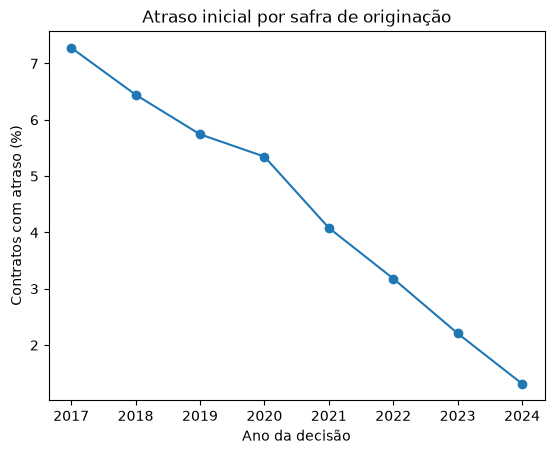

In [4]:
DIAS_ATRASO = 7
rotulos = montar_target(DIAS_ATRASO)
safra = rotulos.groupby(rotulos["data_decisao"].dt.year)["target"].agg(
    contratos="size",
    eventos="sum",
    taxa="mean")

display(safra)
safra.loc[safra.index < 2025, "taxa"].mul(100).plot(
    marker="o", 
    ylabel="Contratos com atraso (%)", 
    xlabel="Ano da decisão", 
    title="Atraso inicial por safra de originação")

plt.show()

Alvo adotado. Um contrato aprovado é positivo se alguma das três primeiras parcelas foi paga mais de 7 dias corridos após o vencimento ou ficou sem pagamento registrado até o fim dessa janela. A base permitiu classificar 101.816 dos 116.182 contratos aprovados (87,6%). Os 14.366 restantes ficaram fora por falta de parcelas com vencimento observável ou de maturidade. 

Na safra de 2024, o corte de 7 dias produziu 238 eventos, contra 78 no corte de 15 dias e 13 no de 30 dias. A primeira versão do vencimento produziria 234 eventos no corte de 7 dias. A diferença é pequena nessa safra, embora o instante em que a revisão ocorreu continue desconhecido. O proxy mede atraso inicial. Uma aplicação voltada a perda financeira exigiria outro desfecho.

A taxa observada passou de 7,28% em 2017 para 1,31% em 2024 entre os contratos rotuláveis. Mudanças de produto, originação e cobertura do rótulo são hipóteses para investigar. A safra de 2025 tem apenas um contrato observável e fica fora da comparação.

**O atraso inicial antecipa atrasos posteriores?**

Na coorte com 180 dias completos após o rótulo e ao menos três parcelas posteriores com pagamento observado nessa janela, comparamos a frequência de atraso superior a 30 dias. A cobertura é exibida por grupo. A coorte exclui contratos sem acompanhamento suficiente. O resultado mede associação com atraso posterior, e a validação de perda financeira requer saldo, baixas e recuperação.

In [11]:

janela_roll = pd.Timedelta(days=180)
base_roll = rotulos.loc[rotulos.data_rotulo.add(janela_roll).le(corte_observacao)]
posteriores = parcelas.loc[parcelas.numero_parcela.gt(3), [
    "id_contrato", "numero_parcela", "data_real_pagamento", "data_prevista_pagamento",
]].join(base_roll[["data_rotulo"]], on="id_contrato", how="inner", validate="many_to_one")
posteriores = posteriores.dropna(subset=["data_real_pagamento", "data_prevista_pagamento"])
posteriores = posteriores.loc[
    posteriores.data_real_pagamento.gt(posteriores.data_rotulo)
    & posteriores.data_real_pagamento.le(posteriores.data_rotulo + janela_roll)
].assign(atraso30=lambda d: (
    d.data_real_pagamento - d.data_prevista_pagamento
).gt(pd.Timedelta(days=30)))
seguimento = posteriores.groupby("id_contrato").agg(
    parcelas_observadas=("numero_parcela", "nunique"), atraso30=("atraso30", "any"),
)
coorte_roll = base_roll.join(seguimento.loc[seguimento.parcelas_observadas.ge(3)], how="inner")
roll = coorte_roll.groupby("target")["atraso30"].agg(
    contratos="size", eventos="sum", taxa="mean",
)
roll["cobertura"] = roll.contratos / base_roll.groupby("target").size()
display(roll)
faltam_iniciais = (
    aprovados.index.difference(rotulos.index)
    .intersection(iniciais.groupby("id_contrato").numero_parcela.nunique().loc[lambda s: s.lt(3)].index)
)
print("Contratos aprovados sem rótulo e com apenas 1 ou 2 parcelas iniciais registradas:",
      len(faltam_iniciais))

,contratos,eventos,taxa,cobertura
target,,,,
0,74057,398,0.005374,0.824587
1,3204,299,0.093321,0.881916


Contratos aprovados sem rótulo e com apenas 1 ou 2 parcelas iniciais registradas: 5581


Na coorte observável, **9,33%** dos contratos com atraso inicial apresentaram atraso posterior superior a 30 dias em até 180 dias, frente a **0,54%** dos demais. A exigênciade três parcelas posteriores observadas seleciona contratos com mais acompanhamento. As taxas são condicionadas a essa coorte. Contratos aprovados sem as três parcelas iniciais ficam sem rótulo, pois a ausência de registro pode refletir encerramento antecipado, ausência de pagamento ou cobertura incompleta.

## 3. Construção das variáveis no momento da solicitação

Os termos da proposta são tipo de contrato, valor solicitado e valor do bem. O dicionário indica que `valor_solicitado`no histórico equivale a `valor_credito` na submissão. Zero no valor solicitado é tratado como ausente, com imputação aprendida no treino. Essa convenção evita interpretar zero como uma exposição real. Em produção, o significado de zero por produto deve ser confirmado. 

Comparamos dois tipos de histórico. O de decisões contém quantidade e recência. O de pagamentos usa a razão entre somas de valores pagos e previstos por registro, atraso superior a sete dias em uma janela retrospectiva de 180 dias e um indicador de ausência de registros. A razão é uma medida de comportamento na base, sensível a pagamentos fracionados e revisões. Ela não representa o saldo contábil.

Como a base contém a data do pagamento, mas não o timestamp de registro no sistema, aplicamos uma defasagem de 30 dias e testamos a sensibilidade sem essa folga. A defasagem é uma hipótese operacional. Para produção, o filtro precisa usar a data de disponibilidade efetiva e a versão do vencimento conhecida na ocasião. 

In [12]:
def montar_sinais(base, data, valor):
    sinais = base[["id_cliente", "tipo_contrato", "valor_bem", data, valor]].copy()
    sinais = sinais.rename(columns={data: "data_evento", valor: "valor_pedido"})
    assert sinais["data_evento"].notna().all() and sinais["id_cliente"].notna().all()
    sinais["ordem"] = np.arange(len(sinais))
    resultado = pd.merge_asof(
        sinais.sort_values("data_evento"),
        historico_diario.sort_values("data_anterior"),
        left_on="data_evento", right_on="data_anterior", by="id_cliente",
        allow_exact_matches=False,
    ).sort_values("ordem").reset_index(drop=True)
    resultado["decisoes_anteriores"] = resultado["decisoes_anteriores"].fillna(0)
    resultado["dias_desde_decisao"] = (resultado.data_evento - resultado.data_anterior).dt.days
    resultado["tipo_contrato"] = resultado["tipo_contrato"].astype("string").fillna("ausente").astype(str)
    return resultado

historico_diario = (
    contratos.assign(data_anterior=contratos.data_decisao.dt.normalize())
    .groupby(["id_cliente", "data_anterior"], as_index=False)
    .size().sort_values("data_anterior")
)
historico_diario["decisoes_anteriores"] = historico_diario.groupby("id_cliente")["size"].cumsum()

# Cortamos por dia nos dois lados para excluir qualquer decisão no mesmo dia.
amostra = contratos.loc[contratos.id_contrato.isin(rotulos.index)].copy()
amostra["data_decisao"] = amostra.data_decisao.dt.normalize()
sub = solicitacoes.assign(data_solicitacao=solicitacoes.data_solicitacao.dt.normalize())
treinavel = montar_sinais(amostra, "data_decisao", "valor_solicitado")
pontuar = montar_sinais(sub, "data_solicitacao", "valor_credito")
assert pontuar.id_cliente.equals(solicitacoes.id_cliente.reset_index(drop=True))
for dados in (treinavel, pontuar):
    assert (dados.data_anterior.isna() | dados.data_anterior.lt(dados.data_evento)).all()
treinavel["target"] = amostra.id_contrato.map(rotulos.target).to_numpy()
treinavel["data_rotulo"] = amostra.id_contrato.map(rotulos.data_rotulo).to_numpy()

In [13]:

for base in (treinavel, pontuar):
    base["valor_pedido"] = base["valor_pedido"].mask(base["valor_pedido"].eq(0))

pag = parcelas[[
    "id_cliente", "id_contrato", "data_real_pagamento", "data_prevista_pagamento",
    "valor_pago_parcela", "valor_previsto_parcela",
]].dropna(subset=["data_real_pagamento"]).join(
    contratos.set_index("id_contrato")[["data_decisao"]], on="id_contrato", validate="many_to_one"
)
pag["dia_pag"] = pag.data_real_pagamento.dt.normalize()
pag = pag.loc[pag.dia_pag.ge(pag.data_decisao.dt.normalize())].copy()
pag["atraso7"] = (pag.data_real_pagamento - pag.data_prevista_pagamento).gt(pd.Timedelta(days=7))
pag["evento_pag"] = 1
diario = pag.groupby(["id_cliente", "dia_pag"], as_index=False).agg(
    pago=("valor_pago_parcela", "sum"),
    devido=("valor_previsto_parcela", "sum"),
    atraso7=("atraso7", "sum"),
    evento_pag=("evento_pag", "sum"),
).sort_values("dia_pag", kind="stable")
contadores = ["pago", "devido", "atraso7", "evento_pag"]
diario[contadores] = diario.groupby("id_cliente")[contadores].cumsum()

def pagamentos_anteriores(base, dias):
    eventos = base[["id_cliente", "data_evento"]].reset_index(drop=True)
    eventos["ordem"] = np.arange(len(eventos))
    eventos["limite"] = eventos.data_evento - pd.Timedelta(days=dias)
    consulta = eventos[["id_cliente", "ordem", "limite"]]

    def acumulado(pontos):
        return pd.merge_asof(
            pontos.sort_values("limite", kind="stable"), diario,
            left_on="limite", right_on="dia_pag", by="id_cliente",
            direction="backward", allow_exact_matches=False,
        ).sort_values("ordem").reset_index(drop=True)

    atual = acumulado(consulta)
    anterior = acumulado(consulta.assign(limite=consulta.limite - pd.Timedelta(days=180)))
    assert (atual.dia_pag.isna() | atual.dia_pag.lt(atual.limite)).all()
    return pd.DataFrame({
        f"razao_pago_devido_{dias}d": (
            atual.pago / atual.devido.where(atual.devido.gt(0))
        ).clip(0, 1.2).to_numpy(),
        f"atraso7_ult_180d_{dias}d": atual.atraso7.fillna(0).gt(anterior.atraso7.fillna(0)).to_numpy(dtype=int),
        f"sem_historico_pag_{dias}d": atual.evento_pag.isna().to_numpy(dtype=int),
    }, index=base.index)

treinavel = treinavel.join(pagamentos_anteriores(treinavel, 30)).join(
    pagamentos_anteriores(treinavel, 0)
)
pontuar = pontuar.join(pagamentos_anteriores(pontuar, 30))

## 4. Discriminação e calibração fora do tempo

Treinamos regressões logísticas com a mesma regularização (C=0,1) em dados de 2022-2023, com rótulos disponíveis antes de 2024. Comparamos as versões em 2024 por ROC-AUC, Average Precision (AP) e Brier. A AP de referência é a prevalência; o Brier avalia o erro quadrático das probabilidades.

A calibração tem uma avaliação própria. Ajustamos somente o intercepto com rótulos maduros antes de julho de 2024 e medimos o efeito nas solicitações do segundo semestre. Na submissão, preservamos o modelo-base e atualizamos o intercep com os contratos de 2024 já maduros na primeira data de pontuação.

In [14]:
inicio_treino = pd.Timestamp("2022-01-01")
inicio_validacao = pd.Timestamp("2024-01-01")
fim_validacao = pd.Timestamp("2025-01-01")
datas = treinavel.data_evento
treino = treinavel.loc[
    datas.ge(inicio_treino) & datas.lt(inicio_validacao)
    & treinavel.data_rotulo.lt(inicio_validacao)
]
validacao = treinavel.loc[datas.ge(inicio_validacao) & datas.lt(fim_validacao)].copy()
assert treino.target.nunique() == validacao.target.nunique() == 2
print(f"Treino: {len(treino):,} contratos, {treino.target.sum():,} eventos")
print(f"Validação: {len(validacao):,} contratos, {validacao.target.sum():,} eventos")

def ajustar(base, colunas):
    numericas = [col for col in colunas if col != "tipo_contrato"
                 and not col.startswith("razao_pago_devido")]
    razao = [col for col in colunas if col.startswith("razao_pago_devido")]
    preparar = ColumnTransformer([
        ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                              StandardScaler()), numericas),
        ("razao", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), razao),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=25), ["tipo_contrato"]),
    ])
    modelo = make_pipeline(preparar, LogisticRegression(C=0.1, max_iter=400))
    return modelo.fit(base[colunas], base.target)

proposta = ["tipo_contrato", "valor_pedido", "valor_bem"]
def colunas_pagamento(dias):
    return [f"{nome}_{dias}d" for nome in
            ("razao_pago_devido", "atraso7_ult_180d", "sem_historico_pag")]

experimentos = {
    "proposta": proposta,
    "proposta + decisões": proposta + ["decisoes_anteriores", "dias_desde_decisao"],
    "proposta + pagamentos (0d)": proposta + colunas_pagamento(0),
    "proposta + pagamentos (30d)": proposta + colunas_pagamento(30),
}
predicoes = {"prevalência de treino": np.full(len(validacao), treino.target.mean())}
modelos = {}
for nome, colunas in experimentos.items():
    modelo = ajustar(treino, colunas)
    modelos[nome] = modelo
    predicoes[nome] = modelo.predict_proba(validacao[colunas])[:, 1]

metricas = []
for nome, pd_estimada in predicoes.items():
    metricas.append({
        "modelo": nome, "ROC-AUC": roc_auc_score(validacao.target, pd_estimada),
        "AP": average_precision_score(validacao.target, pd_estimada),
        "Brier": brier_score_loss(validacao.target, pd_estimada),
        "score médio": pd_estimada.mean(),
        "taxa observada": validacao.target.mean(),
    })
display(pd.DataFrame(metricas).set_index("modelo"))

Treino: 33,785 contratos, 947 eventos
Validação: 18,099 contratos, 238 eventos


,ROC-AUC,AP,Brier,score médio,taxa observada
modelo,,,,,
prevalência de treino,0.500000,0.013150,0.013198,0.028030,0.01315
proposta,0.608268,0.020601,0.013211,0.028532,0.01315
proposta + decisões,0.599757,0.018800,0.013187,0.027738,0.01315
proposta + pagamentos (0d),0.661613,0.032861,0.013062,0.026107,0.01315
proposta + pagamentos (30d),0.654676,0.031175,0.013078,0.026087,0.01315


In [15]:
MODELO_ESCOLHIDO = "proposta + pagamentos (30d)"
escolhido = modelos[MODELO_ESCOLHIDO]
validacao["score"] = predicoes[MODELO_ESCOLHIDO]
validacao["score_proposta"] = predicoes["proposta"]
y = validacao.target.to_numpy()
base_score = validacao.score_proposta.to_numpy()
novo_score = validacao.score.to_numpy()

# Reamostragem pareada por cliente para preservar contratos correlacionados.
grupos = list(validacao.reset_index(drop=True).groupby("id_cliente").indices.values())
rng = np.random.default_rng(42)
deltas = []
for _ in range(500):
    ids = rng.integers(len(grupos), size=len(grupos))
    linhas = np.concatenate([grupos[i] for i in ids])
    deltas.append([
        metrica(y[linhas], novo_score[linhas]) - metrica(y[linhas], base_score[linhas])
        for metrica in (roc_auc_score, average_precision_score)
    ])
display(pd.DataFrame(
    np.quantile(deltas, [.025, .975], axis=0),
    index=["IC 95% inferior", "IC 95% superior"], columns=["Δ ROC-AUC", "Δ AP"],
))

produtos = validacao.tipo_contrato.isin(pontuar.tipo_contrato.unique())
v = validacao.loc[produtos]
display(pd.DataFrame([
    {"modelo": coluna, "n": len(v), "eventos": v.target.sum(),
     "ROC-AUC": roc_auc_score(v.target, v[coluna]),
     "AP": average_precision_score(v.target, v[coluna])}
    for coluna in ("score_proposta", "score")
]))
display(validacao.groupby("atraso7_ult_180d_30d").agg(
    contratos=("target", "size"), taxa_observada=("target", "mean"),
    taxa_proposta=("score_proposta", "mean"), taxa_com_pagamentos=("score", "mean"),
))
display(pd.Series(escolhido[1].coef_[0], index=escolhido[0].get_feature_names_out(),
                  name="coeficiente").sort_values())

,Δ ROC-AUC,Δ AP
IC 95% inferior,0.014298,0.002867
IC 95% superior,0.077345,0.021883


,modelo,n,eventos,ROC-AUC,AP
0,score_proposta,8228,117,0.656663,0.024852
1,score,8228,117,0.680113,0.032319


,contratos,taxa_observada,taxa_proposta,taxa_com_pagamentos
atraso7_ult_180d_30d,,,,
0,17788,0.012368,0.028508,0.025168
1,311,0.057878,0.029872,0.078665


cat__tipo_contrato_Consumer loans    -0.294132
razao__razao_pago_devido_30d         -0.260734
num__missingindicator_valor_bem      -0.174369
num__valor_bem                       -0.158294
num__valor_pedido                    -0.124744
cat__tipo_contrato_Cash loans         0.034817
num__atraso7_ult_180d_30d             0.131602
num__sem_historico_pag_30d            0.183862
cat__tipo_contrato_Revolving loans    0.220786
num__missingindicator_valor_pedido    0.235202
Name: coeficiente, dtype: float64

O modelo com pagamentos defasados é a escolha para a submissão. A comparação com o baseline isola o ganho do comportamento. A comparação com a versão sem defasagem mostra o custo da folga operacional. A avaliação por produto aproxima o mix pontuado, e a análise por atraso anterior mostra como o sinal entra no score. A regressão logística permite inspecionar a direção das associações e calcular contribuições individuais para revisão de decisões.

Na validação de 2024, a ROC-AUC passou de 0,608 para 0,655 e a AP de 0,0206 para 0,0312. Os intervalos pareados de 95% fizeram acima de zero para a diferença de AUC e de AP. Nos produtos presentes na submissão, a AUC passou de 0,657 para 0,680, com 117 eventos. Os 311 contratos com atraso recente tiveram taxa de 5,79%, frente a 1,24% entre os demais. O modelo com pagamentos atribui a esse grupo score médio bruto de 7,87%, frente a 2,99% no baseline. A inclusão do comportamento também reduziu a dependência do valor pedido na submissão. A correlação de Spearman passou de -0,987 para -0,743 entre valores informados, ainda um ponto a monitorar.

Calibração pré-julho: 5,822 contratos, 85 eventos


,score,Brier,média,observado
0,score,0.009860,0.025304,0.009624
1,score_calibrado,0.009551,0.013762,0.009624


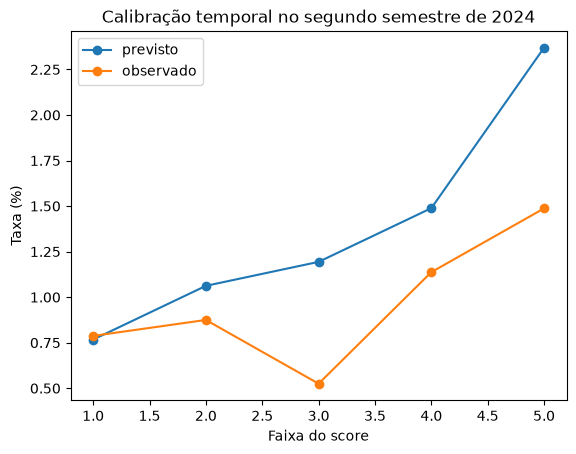

In [16]:

from scipy.optimize import brentq
from scipy.special import expit

def ajustar_intercepto(base):
    logits = escolhido.decision_function(base[experimentos[MODELO_ESCOLHIDO]])
    taxa = base.target.mean()
    assert 0 < taxa < 1
    return brentq(lambda delta: expit(logits + delta).mean() - taxa, -40, 40)

def probabilidade(base, delta):
    return expit(escolhido.decision_function(base[experimentos[MODELO_ESCOLHIDO]]) + delta)

corte_calibracao = pd.Timestamp("2024-07-01")
calibracao = validacao.loc[
    validacao.data_evento.lt(corte_calibracao) & validacao.data_rotulo.lt(corte_calibracao)
]
teste_calibracao = validacao.loc[validacao.data_evento.ge(corte_calibracao)].copy()
delta_teste = ajustar_intercepto(calibracao)
teste_calibracao["score_calibrado"] = probabilidade(teste_calibracao, delta_teste)
print(f"Calibração pré-julho: {len(calibracao):,} contratos, {calibracao.target.sum()} eventos")
display(pd.DataFrame([
    {"score": nome, "Brier": brier_score_loss(teste_calibracao.target, teste_calibracao[nome]),
     "média": teste_calibracao[nome].mean(), "observado": teste_calibracao.target.mean()}
    for nome in ("score", "score_calibrado")
]))
faixas = pd.qcut(teste_calibracao.score_calibrado, 5, duplicates="drop")
calib_faixas = teste_calibracao.groupby(faixas, observed=True).agg(
    previsto=("score_calibrado", "mean"), observado=("target", "mean"),
)
calib_faixas.mul(100).set_axis(range(1, len(calib_faixas) + 1)).plot(
    marker="o", xlabel="Faixa do score", ylabel="Taxa (%)",
    title="Calibração temporal no segundo semestre de 2024",
)
plt.show()


## 5. Política de crédito proposta

**Modo Sombra:**

Durante seis meses, registrar score, versão, dados disponíveis, decisão vigente e desfecho quando maduro. Como referências iniciais de saída, exigir AUC acima de 0,60, captura no top 5% acima de 10% e razão entre probabilidade média e taxa observada de 0,8 a 1,2. Avaliar por safra e produto, com volume mínimo de eventos definido pelo comitê. PSI acima de 0,25 é um gatilho inicial de investigação e suspensão de expansão. Após validação, testar um piloto controlado com regras abaixo.


**Faixas do Piloto:**

Dentro da população já elegível pelas regras de crédito, aprovar até o percentil 80 de risco se a capacidade de pagamento estiver confirmada. Entre P80 e P95, testar menor valor ou outra condição que reduza a exposição sem aumentar o comprometimento de renda. Acima de P95, encaminhar para revisão manual. Atraso recente de mais de sete dias também aciona revisão. Como cenário, comprometimento de renda acima de 30% aciona ajuste após validação de renda e das demais obrigações. Dados insuficientes seguem para revisão. A tabela simula apenas as faixas do score; as regras complementares podem alterar volumes.


**Recusa:** 

Considerar recusa após revisão quando nenhuma condição elegível tiver margem esperada positiva. Para margem líquida em operações adimplentes M e perda líquida em caso de default L, o PD de equilíbrio é M/(M+L). Com perda de 50% do saldo, margens de 3%, 5% e 8% correspondem a PDs de equilíbrio de 5,7%, 9,1% e 13,8%. Esse limiar exige um modelo de default e dados de perda e margem. O roll rate de atraso posterior sustenta a triagem, mas a conversão para PD de perda requer estimativas próprias. A recusa automática fica fora do piloto.


**Registro e Revisão:**

Guardar regra aplicada, versão e fatores verificáveis, como atraso recente registrado ou comprometimento comprovado. Coeficientes e contribuições ao logit ajudam a auditoria e a revisão humana. Monitorar volume por faixa, exposição, calibração, estabilidade, desempenho por produto e impactos por grupo.

In [17]:
ordenada = validacao.sort_values("score", ascending=False, kind="stable")
cenarios = []
for capacidade in (.02, .05, .10):
    fila = ordenada.head(int(np.ceil(capacidade * len(ordenada))))
    cenarios.append({
        "capacidade": capacidade, "contratos revisados": len(fila),
        "eventos na fila": fila.target.sum(),
        "captura dos eventos": fila.target.sum() / ordenada.target.sum(),
        "taxa na fila": fila.target.mean(),
        "lift sobre a carteira": fila.target.mean() / ordenada.target.mean(),
    })
display(pd.DataFrame(cenarios))
cortes = calibracao.score.quantile([.8, .95])
teste_politica = teste_calibracao.assign(acao=np.select(
    [teste_calibracao.score.le(cortes.loc[.8]), teste_calibracao.score.le(cortes.loc[.95])],
    ["Aprovação elegível", "Avaliar ajuste de condições"],
    default="Revisão manual",
))
politica = teste_politica.groupby("acao")["target"].agg(
    contratos="size", eventos="sum", taxa_atraso="mean",
)
politica["participacao"] = politica.contratos / len(teste_politica)
display(politica)


,capacidade,contratos revisados,eventos na fila,captura dos eventos,taxa na fila,lift sobre a carteira
0,0.02,362,24,0.100840,0.066298,5.041738
1,0.05,905,37,0.155462,0.040884,3.109072
2,0.10,1810,55,0.231092,0.030387,2.310797


,contratos,eventos,taxa_atraso,participacao
acao,,,,
Aprovação elegível,4747,38,0.008005,0.830621
Avaliar ajuste de condições,753,12,0.015936,0.131759
Revisão manual,215,5,0.023256,0.037620


Os cortes do piloto são estimados na coorte madura disponível antes de julho e aplicados no segundo semestre. As participações medem a distribuição retrospectiva entre ações no conjunto aprovado e com rótulo. São referências de capacidade e de risco, com aprovação e perda após intervenção a medir prospectivamente.

Em 2024, a fila retrospectiva de 5% reuniu 905 contratos e 37 eventos (15,5% dos atrasos). Aplicando os cortes estimados antes de julho ao segundo semestre, a distribuição ficou em 83,1% elegíveis à aprovação, 13,2% para avaliar ajustes e 3,8% para revisão. As taxas de atraso foram 0,80%, 1,59% e 2,33%, respectivamente. São estimativas com poucos eventos nas faixas superiores.

No segundo semestre, a calibração reduziu o Brier de 0,009860 para 0,009551. O score médio caiu de 2,53% para 1,38%, frente a 0,96% observado. A calibração ainda ficou fora da margem proposta para saída do modo sombra.

## 6. Submissão e operação
A calibração final usa apenas rótulos de 2024 maduros antes da primeira solicitação. Mantemos fixos os coeficientes do modelo-base para calibrar previsões fora da amostra de treino. Como a calibração atualiza somente o intercepto, a ordem dos scores é preservada.

Em produção, publicar por cliente a versão das variáveis de pagamento e o timestamp de disponibilidade. O serviço de decisão combina essa consulta com os dados da proposta. Acompanhar ausência de histórico, cobertura, latência e atualização do cache. A calibração deriva da população aprovada observável e pode mudar no conjunto de todas as solicitações.

O ZIP de entrega deve conter o código, as instruções e o CSV de submissão. O enunciado pede anonimato e exclui as bases fornecidas e arquivos intermediários.

In [18]:
corte_submissao = pontuar.data_evento.min()
calibracao_final = validacao.loc[
    validacao.data_evento.lt(corte_submissao) & validacao.data_rotulo.lt(corte_submissao)
]
delta_final = ajustar_intercepto(calibracao_final)
arquivo = solicitacoes[["id_cliente"]].copy()
arquivo["probabilidade_inadimplencia"] = probabilidade(pontuar, delta_final)
assert arquivo.id_cliente.is_unique
assert arquivo.id_cliente.equals(solicitacoes.id_cliente)
assert arquivo.probabilidade_inadimplencia.between(0, 1).all()
arquivo.to_csv("submissao_case.csv", index=False, float_format="%.8f")
print(f"Calibração final: {len(calibracao_final):,} contratos até {corte_submissao.date()}, "
      f"intercepto ajustado em {delta_final:+.3f}")
print(f"CSV: {len(arquivo):,} linhas, score médio {arquivo.probabilidade_inadimplencia.mean():.2%}")
diagnostico = pontuar.assign(
    score_proposta=modelos["proposta"].predict_proba(pontuar[proposta])[:, 1],
    score_com_pagamentos=arquivo.probabilidade_inadimplencia.to_numpy(),
)
display(diagnostico[["valor_pedido", "score_proposta", "score_com_pagamentos"]]
        .corr(method="spearman")["valor_pedido"])

Calibração final: 17,771 contratos até 2025-02-04, intercepto ajustado em -0.698
CSV: 40,000 linhas, score médio 1.12%


valor_pedido            1.000000
score_proposta         -0.986546
score_com_pagamentos   -0.743287
Name: valor_pedido, dtype: float64

## 7. Considerações finais
A organização segue o fluxo de uma decisão de crédito: definir um desfecho observável, reconstruir as informações que existiriam na solicitação, medir a capacidade de ordenar risco fora do tempo e traduzir os resultados em ações. A separação entre ranking e calibração preserva a leitura de cada teste.

A regressão logística regularizada permite verificar o valor incremental do comportamento de pagamento com poucos parâmetros e fornece contribuições inspecionáveis para revisão. LightGBM e XGBoost podem capturar interações e relações não lineares. Uma comparação futura deve medir se o ganho se mantém fora do tempo e se melhora a captura na capacidade real de revisão, a calibração e a estabilidade. O score entregue tem finalidade de risco de atraso inicial. O avanço para decisão vinculante depende do piloto, da avaliação da capacidade de pagamento e da validação econômica.